# HR Attrition Data Analysis

## Project Overview

The objective of this project is to analyze employee attrition patterns, identify factors associated with higher attrition, and provide data-driven recommendations to help HR improve employee retention.

## Data Understanding

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
df = pd.read_csv(r"C:\Users\acer\Downloads\HR dataset.csv")


In [61]:
print(df.head())
df.info()

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

## Data Quality Checks

In [62]:
print(df.shape)
df.isna().sum()
print(df.duplicated().sum())
print(df["Department"].unique())
print(df["Gender"].unique())
print(df["JobRole"].unique())
print(df["MaritalStatus"].unique())
print(df["Attrition"].unique())
print(df["OverTime"].unique())
print(df["Over18"].unique())
print(df["EducationField"].unique())
print(df["BusinessTravel"].unique())

(1470, 35)
0
<StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
<StringArray>
['Female', 'Male']
Length: 2, dtype: str
<StringArray>
[          'Sales Executive',        'Research Scientist',
     'Laboratory Technician',    'Manufacturing Director',
 'Healthcare Representative',                   'Manager',
      'Sales Representative',         'Research Director',
           'Human Resources']
Length: 9, dtype: str
<StringArray>
['Single', 'Married', 'Divorced']
Length: 3, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str
<StringArray>
['Y']
Length: 1, dtype: str
<StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str
<StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str


In [63]:
print(df["Age"].describe())     ##that's why over18 was only yes because the min. is 18 here
print(df["MonthlyIncome"].describe())

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64
count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64


## Exploratory Data Analysis

16.122448979591837


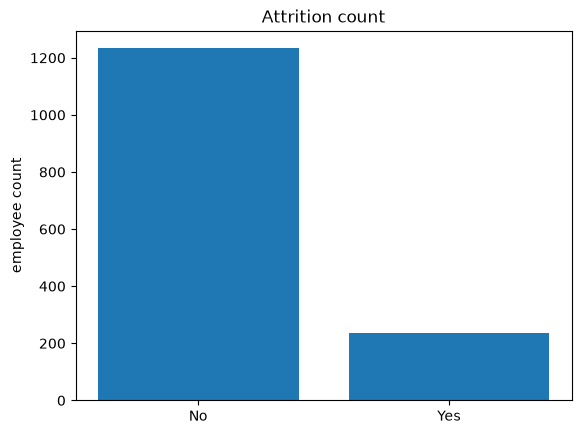

In [64]:
Attrition = df.groupby("Attrition").size()
AttritionRate = (df.groupby("Attrition").size()["Yes"])*100.0/(df.groupby("Attrition").size().sum())
print(AttritionRate)
plt.bar(Attrition.index, Attrition.values)
plt.ylabel("employee count")
plt.title("Attrition count")
plt.show()

Attrition rate = 16.12%,  That means approximately 16 out of every 100 employees in this dataset have an attrition status of Yes


Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92


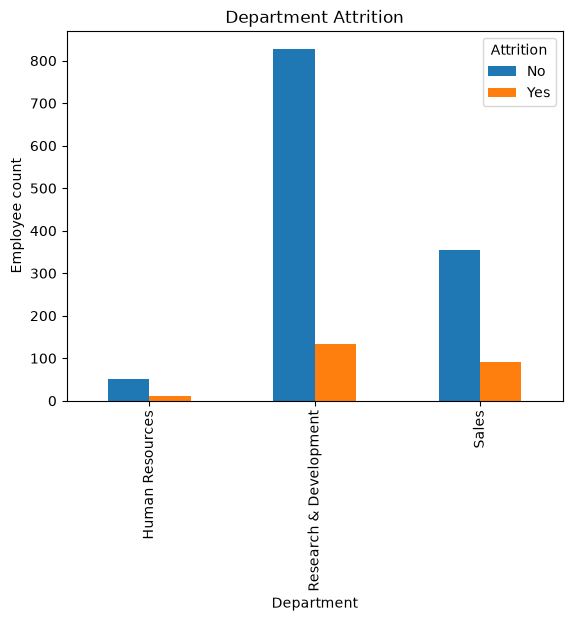

In [65]:
DeptAttrition = df.groupby(["Department","Attrition"]).size().unstack()
DeptAttritionRate = df.groupby("Department")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(DeptAttrition)
DeptAttrition.plot(kind="bar")
plt.ylabel("Employee count")
plt.title("Department Attrition")
plt.show()


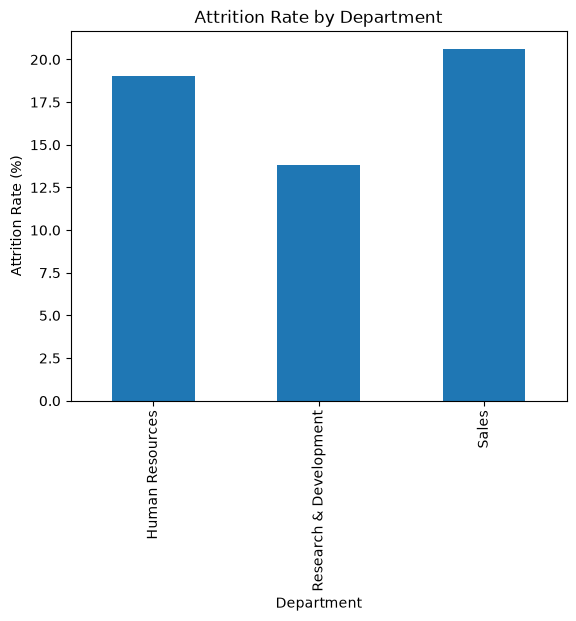

In [66]:
DeptAttritionRate.plot(kind="bar")

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Department")
plt.show()

OverTime
No     10.436433
Yes    30.528846
Name: Attrition, dtype: float64


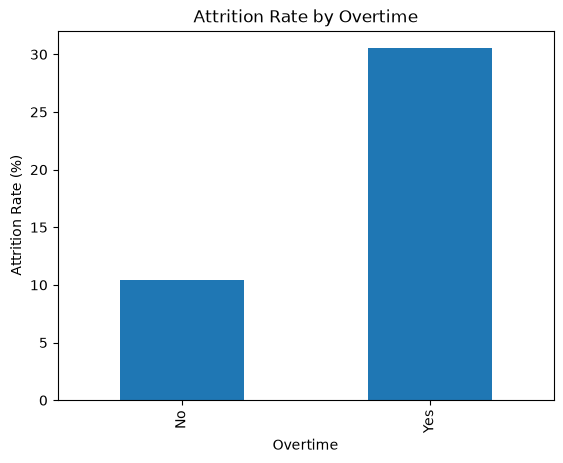

In [67]:
OverTimeAttritionRate = df.groupby("OverTime")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(OverTimeAttritionRate)
OverTimeAttritionRate.plot(kind="bar")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Overtime")
plt.show()


The attrition rate among employees working overtime is about 2.93 times the rate among employees not working overtime.


JobSatisfaction
1    22.837370
2    16.428571
3    16.515837
4    11.328976
Name: Attrition, dtype: float64


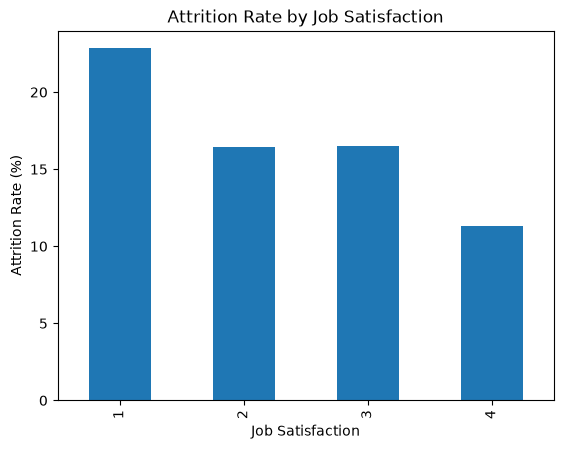

In [68]:
JobSatisAttritionRate = df.groupby("JobSatisfaction")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(JobSatisAttritionRate)
JobSatisAttritionRate.plot(kind="bar")
plt.xlabel("Job Satisfaction")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Job Satisfaction")
plt.show()


Gender
Female    14.795918
Male      17.006803
Name: Attrition, dtype: float64


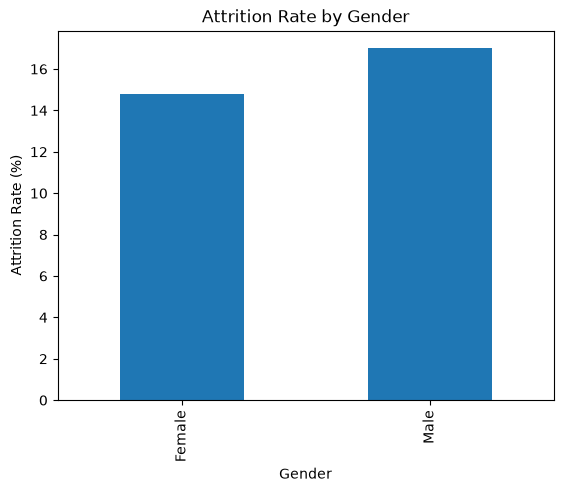

In [69]:
GenderAttritionRate = df.groupby("Gender")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(GenderAttritionRate)
GenderAttritionRate.plot(kind="bar")
plt.xlabel("Gender")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Gender")
plt.show()

YearsAtCompany
0      44
1     171
2     127
3     128
4     110
5     196
6      76
7      90
8      80
9      82
10    120
11     32
12     14
13     24
14     18
15     20
16     12
17      9
18     13
19     11
20     27
21     14
22     15
23      2
24      6
25      4
26      4
27      2
29      2
30      1
31      3
32      3
33      5
34      1
36      2
37      1
40      1
dtype: int64
YearsAtCompany
0      36.363636
1      34.502924
2      21.259843
3      15.625000
4      17.272727
5      10.714286
6      11.842105
7      12.222222
8      11.250000
9       9.756098
10     15.000000
11      6.250000
12      0.000000
13      8.333333
14     11.111111
15      5.000000
16      8.333333
17     11.111111
18      7.692308
19      9.090909
20      3.703704
21      7.142857
22      6.666667
23     50.000000
24     16.666667
25      0.000000
26      0.000000
27      0.000000
29      0.000000
30      0.000000
31     33.333333
32     33.333333
33     20.000000
34      0.000000
36      0

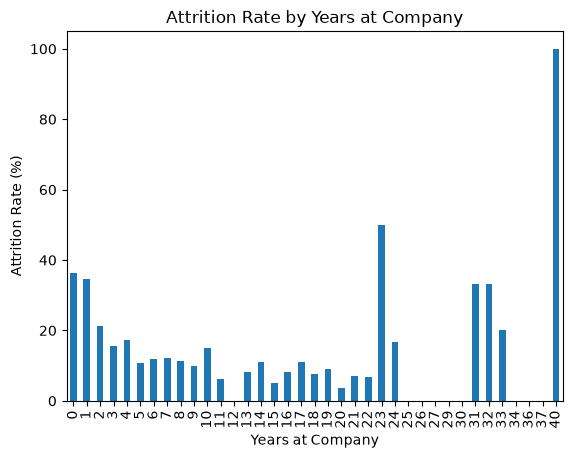

In [70]:
YOEAttrition = df.groupby("YearsAtCompany").size()
print(YOEAttrition)
YOEAttritionRate = df.groupby("YearsAtCompany")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(YOEAttritionRate)
YOESummary = pd.concat([YOEAttrition, YOEAttritionRate], axis=1)
YOESummary.columns = ["EmployeeCount", "AttritionRate"]
print(YOESummary)
YOESummary["AttritionRate"].plot(kind="bar")
plt.xlabel("Years at Company")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Years at Company")
plt.show()


In [71]:
p25 = np.percentile(df["MonthlyIncome"], 25)
p75 = np.percentile(df["MonthlyIncome"], 75)

In [72]:
df["IncomeGroup"] = np.where(df["MonthlyIncome"] <= p25, "Low", np.where(df["MonthlyIncome"] > p75, "High", "Medium"))
print(df["IncomeGroup"].value_counts())


IncomeGroup
Medium    733
Low       369
High      368
Name: count, dtype: int64


IncomeGroup
High      10.326087
Low       29.268293
Medium    12.414734
Name: Attrition, dtype: float64


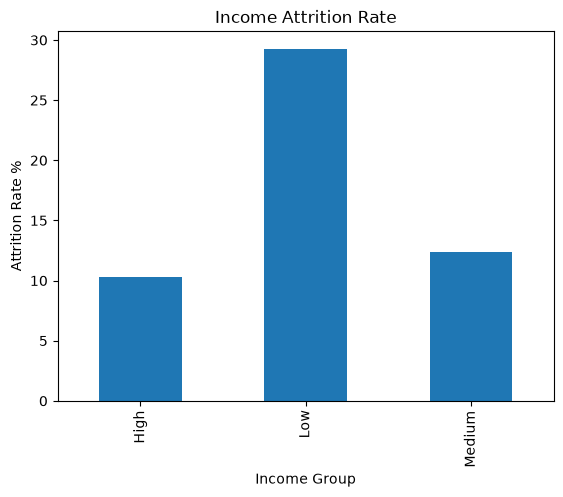

In [73]:
IncomeAttritionRate = df.groupby("IncomeGroup")["Attrition"].apply(lambda x: (x == "Yes").mean() * 100)
print(IncomeAttritionRate)  
IncomeAttritionRate.plot(kind = "bar")
plt.ylabel("Attrition Rate %")
plt.xlabel("Income Group")
plt.title("Income Attrition Rate")
plt.show()

Lower-income employees in this dataset are more likely to leave than employees in the medium- and high-income groups. Compensation could be one factor worth investigating, but this analysis alone doesn't establish that low salary causes attrition.

In [74]:
OverTimeIcomeGroupRate = df.groupby(["OverTime", "IncomeGroup"])["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100)

In [75]:
OverTimeIncomeGroupAtt = df.groupby(["OverTime", "IncomeGroup"])["Attrition"].size()

In [76]:
EmployeesLeft = df[df["Attrition"] == "Yes"].groupby(["OverTime", "IncomeGroup"]).size()
print(EmployeesLeft)

OverTime  IncomeGroup
No        High           19
          Low            46
          Medium         45
Yes       High           19
          Low            62
          Medium         46
dtype: int64


In [77]:
IncomeOverTimeSummary = pd.concat(
    [OverTimeIcomeGroupRate, OverTimeIncomeGroupAtt, EmployeesLeft],
    axis=1
)

IncomeOverTimeSummary.columns = [
    "AttritionRate",
    "EmployeeCount",
    "EmployeesLeft"
]

IncomeOverTimeSummary

AttritionRate  EmployeeCount  EmployeesLeft
OverTime IncomeGroup                                             
No       High              7.224335            263             19
         Low              17.490494            263             46
         Medium            8.522727            528             45
Yes      High             18.095238            105             19
         Low              58.490566            106             62
         Medium           22.439024            205             46

In [78]:
IncomeOverTimeSummary = IncomeOverTimeSummary.reset_index()
IncomeOverTimeSummary

,OverTime,IncomeGroup,AttritionRate,EmployeeCount,EmployeesLeft
0,No,High,7.224335,263,19
1,No,Low,17.490494,263,46
2,No,Medium,8.522727,528,45
3,Yes,High,18.095238,105,19
4,Yes,Low,58.490566,106,62
5,Yes,Medium,22.439024,205,46


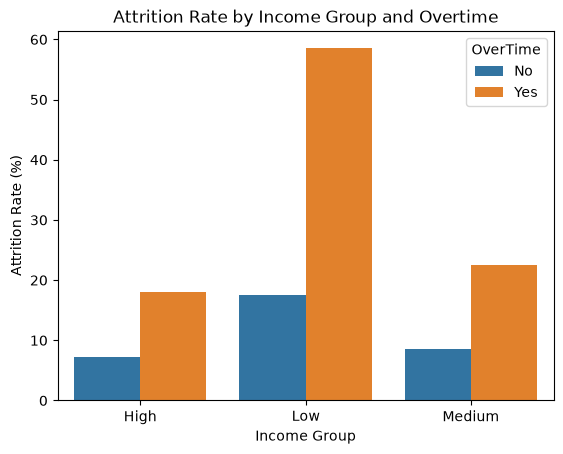

In [79]:
sns.barplot(
    data=IncomeOverTimeSummary,
    x="IncomeGroup",
    y="AttritionRate",
    hue="OverTime")
plt.xlabel("Income Group")
plt.ylabel("Attrition Rate (%)")
plt.title("Attrition Rate by Income Group and Overtime")
plt.show()


The data suggests a strong association between low income, working overtime, and higher employee attrition. Employees in the Low Income + Overtime group have the highest attrition rate, at 58.49%, compared with 17.49% for low-income employees who do not work overtime.


In [80]:
LowIncomeOvertime = df[
    (df["OverTime"] == "Yes") &
    (df["IncomeGroup"] == "Low")]

LowIncomeOvertime.shape

(106, 36)

In [81]:
LowIncomeOvertime.groupby(["JobRole", "Attrition"]).size()

JobRole                Attrition
Human Resources        No            2
                       Yes           4
Laboratory Technician  No           12
                       Yes          18
Research Scientist     No           24
                       Yes          26
Sales Representative   No            6
                       Yes          14
dtype: int64

In [82]:
LowIncomeOvertime.groupby("JobRole")["Attrition"].apply(lambda x : (x == "Yes").mean()*100)

JobRole
Human Resources          66.666667
Laboratory Technician    60.000000
Research Scientist       52.000000
Sales Representative     70.000000
Name: Attrition, dtype: float64

In [83]:
LowIncomeOvertime.groupby("JobSatisfaction")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100)

JobSatisfaction
1    65.217391
2    66.666667
3    56.666667
4    50.000000
Name: Attrition, dtype: float64

In [84]:
LowIncomeOvertime.groupby("JobSatisfaction")["Attrition"].value_counts().unstack(fill_value=0)


Attrition,No,Yes
JobSatisfaction,,
1,8,15
2,7,14
3,13,17
4,16,16


Employees reporting job satisfaction levels 1 and 2 had attrition rates of approximately 65–67%, compared with 50% among employees reporting level 4. This suggests that job satisfaction may be associated with employee attrition, although it does not fully explain the pattern.

In [85]:
LowIncomeOvertime.groupby("JobLevel")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100)

JobLevel
1    60.784314
2     0.000000
Name: Attrition, dtype: float64

In [86]:
LowIncomeOvertime.groupby(["JobLevel", "Attrition"]).size().unstack(fill_value=0)

Attrition,No,Yes
JobLevel,,
1,40,62
2,4,0


In [87]:
LowIncomeOvertime.groupby("YearsAtCompany")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

YearsAtCompany
0     100.000000
1      76.000000
2      46.153846
3      60.000000
4      30.769231
5      66.666667
6      33.333333
7      57.142857
8      33.333333
9      33.333333
10    100.000000
11      0.000000
20      0.000000
Name: Attrition, dtype: float64

In [88]:
LowIncomeOvertime.groupby(
    ["YearsAtCompany", "Attrition"]
).size().unstack(fill_value=0)

Attrition,No,Yes
YearsAtCompany,,
0,0,7
1,6,19
2,7,6
3,6,9
4,9,4
5,3,6
6,2,1
7,3,4
8,4,2


In [89]:
df.groupby("WorkLifeBalance")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

WorkLifeBalance
1    31.250000
2    16.860465
3    14.221725
4    17.647059
Name: Attrition, dtype: float64

In [90]:
df.groupby(["WorkLifeBalance", "Attrition"]).size().unstack(fill_value=0)

Attrition,No,Yes
WorkLifeBalance,,
1,55,25
2,286,58
3,766,127
4,126,27


In [91]:
df.groupby(["JobLevel", "OverTime"])["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

JobLevel  OverTime
1         No          15.762274
          Yes         52.564103
2         No           6.701031
          Yes         17.808219
3         No          12.258065
          Yes         20.634921
4         No           2.739726
          Yes          9.090909
5         No           3.921569
          Yes         16.666667
Name: Attrition, dtype: float64

In [92]:
df.groupby(["JobLevel", "OverTime"])["Attrition"].value_counts()

JobLevel  OverTime  Attrition
1         No        No           326
                    Yes           61
          Yes       Yes           82
                    No            74
2         No        No           362
                    Yes           26
          Yes       No           120
                    Yes           26
3         No        No           136
                    Yes           19
          Yes       No            50
                    Yes           13
4         No        No            71
                    Yes            2
          Yes       No            30
                    Yes            3
5         No        No            49
                    Yes            2
          Yes       No            15
                    Yes            3
Name: count, dtype: int64

The analysis shows that employees working overtime have higher attrition rates than employees not working overtime across all five job levels. The largest difference is observed at JobLevel 1, where attrition is 52.56% among overtime employees compared with 15.76% among non-overtime employees. A total of 82 out of 156 overtime employees at JobLevel 1 left the organization. This suggests that employees at the lowest job level who work overtime may be an important group for further retention investigation. However, the findings show an association rather than causation, and the smaller sample sizes at higher job levels should be considered when interpreting their percentages.

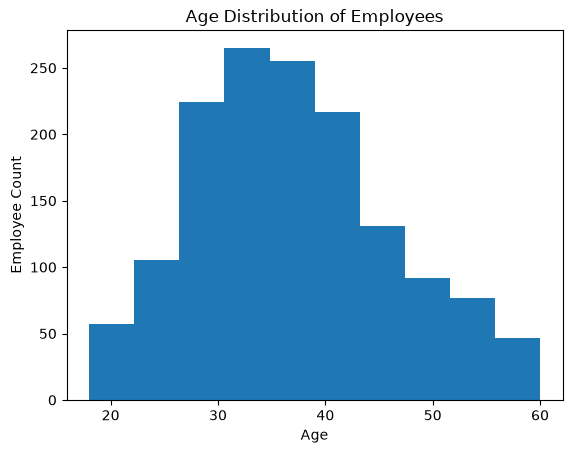

In [93]:
plt.hist(df["Age"])
plt.xlabel("Age")
plt.ylabel("Employee Count")
plt.title("Age Distribution of Employees")
plt.show()

The age distribution indicates that the workforce is primarily concentrated in the 27–42 age range, with the highest employee counts around the early-to-mid 30s. Employee representation declines toward the younger and older ends of the age range. This provides an overview of the organization's workforce composition but does not directly explain attrition patterns.

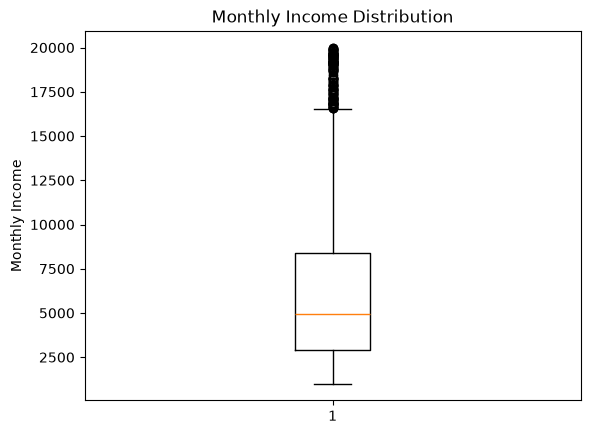

In [94]:
plt.boxplot(df["MonthlyIncome"])
plt.ylabel("Monthly Income")
plt.title("Monthly Income Distribution")
plt.show()

The monthly income distribution is right-skewed, with a median of approximately ₹4,919 and a substantial spread in employee incomes. Several higher-income observations fall beyond the box plot's upper whisker. These values should be checked against business context before deciding whether any data cleaning is necessary.

In [95]:
MonthlyIncome_Cleaned = df["MonthlyIncome"].copy()

Q1 = MonthlyIncome_Cleaned.quantile(0.25)
Q3 = MonthlyIncome_Cleaned.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

MonthlyIncome_Cleaned = MonthlyIncome_Cleaned.clip(
    lower=lower_bound,
    upper=upper_bound
)

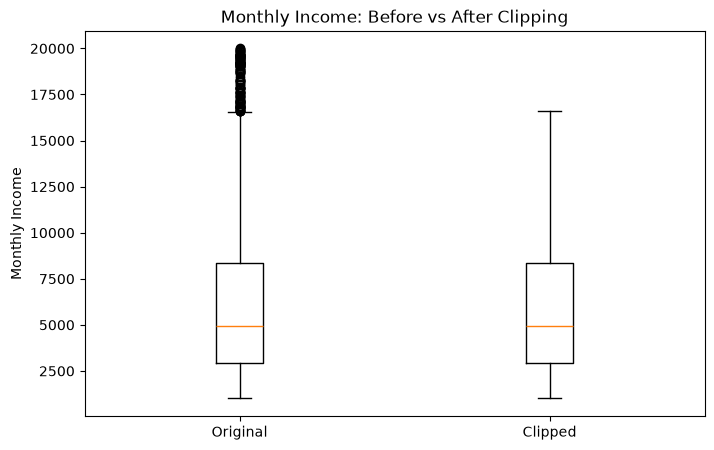

In [96]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [df["MonthlyIncome"], MonthlyIncome_Cleaned],
    tick_labels=["Original", "Clipped"]
)

plt.ylabel("Monthly Income")
plt.title("Monthly Income: Before vs After Clipping")
plt.show()

The original box plot shows a right-skewed income distribution with potential high-income outliers. After clipping, extreme values are capped at the calculated IQR boundaries. This comparison demonstrates the effect of clipping; however, the original income values are retained for the main analysis because these values are not necessarily errors.

In [97]:
print("Original maximum:", df["MonthlyIncome"].max())
print("Clipped maximum:", MonthlyIncome_Cleaned.max())

print("Original minimum:", df["MonthlyIncome"].min())
print("Clipped minimum:", MonthlyIncome_Cleaned.min())

Original maximum: 19999
Clipped maximum: 16581
Original minimum: 1009
Clipped minimum: 1009


clipping reduces the influence of extreme high values on the range of the data without removing employee records.

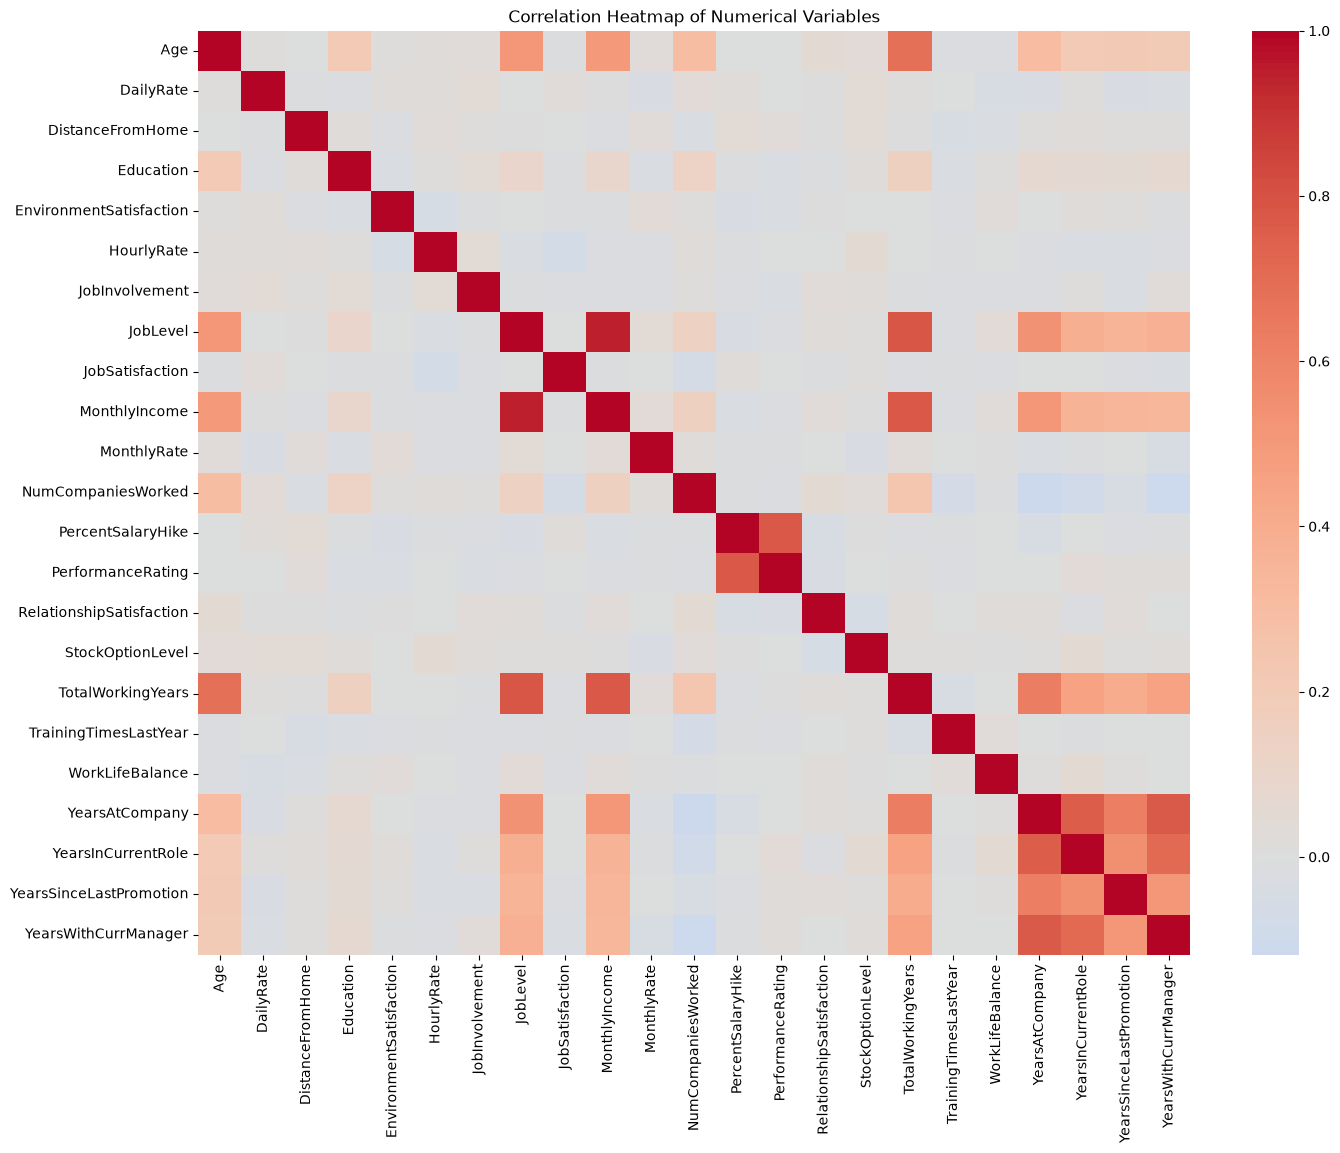

In [98]:
numeric_df = df.select_dtypes(include="number")

numeric_df = numeric_df.drop(
    columns=["EmployeeNumber"],
    errors="ignore"
)

numeric_df = numeric_df.loc[:, numeric_df.nunique() > 1]

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


Employees with higher job levels tend to have higher monthly incomes. Employees with more total working experience also tend to have higher job levels. These are relationships in the data, not proof that one variable causes another.

## Business Questions and Findings

Our analysis identified several factors associated with higher employee attrition. Employees working overtime had an attrition rate of approximately 30.5%, employees in the low-income group had a rate of 29.3%, and employees with the lowest work-life balance rating had a rate of 31.3%.
##These findings suggest potential relationships between overtime, income, work-life balance, and employee attrition. However, they do not establish causation. Further investigation would be needed to determine whether these factors independently contribute to attrition and how they interact with other employee characteristics.

Our analysis found that low-income employees who work overtime have an attrition rate of 58.49% (62 out of 106 employees). This is considerably higher than the overall attrition rate of 16.12%, making this group a priority for further investigation.
##HR should investigate possible contributing factors, such as workload, compensation, job satisfaction, and work-life balance, before deciding on targeted retention measures. This association does not establish that low income and overtime cause employees to leave.

HR can use these findings to prioritize further investigation into areas associated with higher employee attrition, particularly overtime, low income, and poor work-life balance. HR should examine workload distribution, compensation fairness, employee satisfaction, and work-life balance to better understand the potential contributing factors. Based on the additional evidence, the organization can implement targeted retention initiatives and monitor whether attrition rates improve over time.

## Recommendations and Conclusion

Based on the analysis, HR should prioritize investigating the factors associated with higher employee attrition, particularly overtime, low income, and poor work-life balance. Employees working overtime had an attrition rate of approximately 30.5%, while employees in the low-income group had a rate of 29.3%. The low-income employees who also worked overtime showed an even higher attrition rate of 58.49% (62 out of 106 employees), making this group a priority for further investigation. HR should review workload distribution, compensation fairness, employee satisfaction, and work-life balance to better understand the reasons behind these patterns. The organization can then develop targeted retention strategies, such as improving workload management, reviewing compensation practices, and strengthening employee support initiatives. Finally, HR should monitor attrition rates over time to evaluate whether these measures are effective. These findings indicate associations rather than proven causes, so further investigation is necessary before drawing conclusions about why employees leave.